# Binomial trees in SigAlg III: pricing

This is the third of three notebooks on risk-neutral valuation in SigAlg with binomial trees. It uses the binomial model and the claims constructed in the first two notebooks, with the model rebuilt below so that this notebook runs on its own.

We develop the equivalent martingale measure, the self-financing replicating portfolio that justifies risk-neutral pricing, and, for claims that allow early exercise, the optimal stopping times that extend the pricing formula to American-style options.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jmyers7/sigalg/blob/main/docs/notebooks/binomial-pricing-model-3.ipynb)

In [1]:
# If running in Google Colab, uncomment the line below and run this cell first.
# Also, for Mac+Chrome users, beware of a known bug with LaTeX rendering in Colab: https://github.com/googlecolab/colabtools/issues/3192

# !pip install sigalg

## Pricing contingent claims

### Equivalent martingale measures (a.k.a., risk-neutral measures)

The unexplained parameter $R$ appearing in the previous notebooks is the per-period risk-free gross return, which is used to price contingent claims using binomial models. This is the amount of money resulting from $\$1$ invested at a per-period risk-free rate of $r$, and so $R = 1+r$. We will refer to this risk-free investment as a *bond*, and the risky asset whose price process is a binomial model $S_t$ will be called a *stock*.

The absence of arbitrage opportunities in the two-asset market implies (and is equivalent to) the pair of inequalities
$$
    d < R < u,
$$
where $u$ and $d$ are the up- and down-factors of the binomial model, respectively. Thus, the numbers
$$
q_u \stackrel{\text{def}}{=} \frac{R-d}{u-d}, \qquad q_d \stackrel{\text{def}}{=} 1-q_u = \frac{u-R}{u-d}
$$
are probabilities, called the *risk-neutral probabilities*, and they may be computed using SigAlg.

In [2]:
import sigalg as sa

S_0, u, d, p_u, R, T = 100, 1.1, 0.9, 0.7, 1.05, 3

S = sa.BinomialPricingModel.generate(
    initial_price=S_0,
    up_factor=u,
    down_factor=d,
    up_prob=p_u,
    risk_free_gross_return=R,
    mode="enum",
    length=T,
    name="S",
)

q_u, q_d = S.risk_neutral_probs()
print(q_u, q_d)

0.7499999999999999 0.2500000000000001


If $p_u$ and $p_d$ are the real-world probabilities of an upward and downward move of the price, and if $(s_0,s_1,\ldots,s_T)$ is a price trajectory, then we saw that
$$
P(S_0=s_0,S_1=s_1,\ldots,S_T=s_T) = p_u^n p_d^{T-n},
$$
where $n$ is the number of up-moves in the trajectory and $P$ is the real-world measure. If we replace $p_u$ with $q_u$ and $p_d$ with $q_d$, then we get a second measure $Q$ defined by setting
$$
Q(S_0=s_0,S_1=s_1,\ldots,S_T=s_T) = q_u^n q_d^{T-n}.
$$
This latter measure is called the *risk-neutral measure* or *equivalent martingale measure* (*EMM*). SigAlg allows us to compare these two measures.

In [3]:
P = S.prob_measure  # real-world measure
Q = S.emm()  # EMM

print(S)
print(P)
print(Q)

Binomial price process 'S':
t          0      1      2      3
omega                            
0      100.0  110.0  121.0  133.1
1      100.0  110.0  121.0  108.9
2      100.0  110.0   99.0  108.9
3      100.0  110.0   99.0   89.1
4      100.0   90.0   99.0  108.9
5      100.0   90.0   99.0   89.1
6      100.0   90.0   81.0   89.1
7      100.0   90.0   81.0   72.9
Probability measure 'P':
           P
omega       
0      0.343
1      0.147
2      0.147
3      0.063
4      0.147
5      0.063
6      0.063
7      0.027
Probability measure 'Q':
              Q
omega          
0      0.421875
1      0.140625
2      0.140625
3      0.046875
4      0.140625
5      0.046875
6      0.046875
7      0.015625


The "martingale" part of the name *equivalent martingale measure* comes from the fact that the discounted price process is a martingale with respect to $Q$. We recall that this means that
$$
S_t = \frac{1}{R^{r-t}} E_Q(S_r \mid \mathcal{F}_t)
$$
for all $0 \leq t \leq r \leq T$. On the right is an expectation conditioned on a $\sigma$-algebra. The reader unfamiliar with $\sigma$-algebras need not worry; in this special case, this just means that the expectation is conditioned on the random variables $S_0,S_1,\ldots,S_t$.

SigAlg provides both a method to discount the price process $S_t$, as well as a method to check for the martingale property.

In [4]:
S.discount(gross_return=R).is_martingale(prob_measure=Q)

True

### Pricing non-early-exercise claims

One motivation for risk-neutral pricing of contingent claims comes from the theory of replicating portfolios and the absence of arbitrage.

Let $\Phi_t$ be a non-early-exercise contingent claim on a stock with price process $S_t$ with maturity $T$. We suppose that an investor manages a position in both the risk-less bond and the risky stock. Write $B_t$ for the cash position in the bond at time $t$, and $\Delta_t$ for the number of units of stock held at time $t$. We allow $B_t$ and $\Delta_t$ to take on all real values, including negative ones, which represent short positions. The value of the two-asset portfolio at time $t$ is given by the process $V_t$ with
$$
V_t = B_t + S_t \Delta_t.
$$
One time unit later, at time $t+1$, this portfolio will evolve to have value
$$
RB_t + S_{t+1} \Delta_t.
$$
Also at time $t+1$, we imagine that the investor adjusts their positions in the bond and stock, giving a new portfolio value
$$
V_{t+1} = B_{t+1} + S_{t+1} \Delta_{t+1}.
$$
The portfolio is called *self-financing* if the evolved value of the "old" portfolio from time $t$ is equal to the "new" portfolio value at time $t+1$:
$$
V_{t+1} = RB_t + S_{t+1} \Delta_t.
$$
A self-financing portfolio is called a *replicating portfolio* of the non-early-exercise contingent claim $\Phi_t$ if
$$
\Phi_T = RB_{T-1} + S_{T} \Delta_{T-1}.
$$
If we write $X_t$ for the price process of the contingent claim, then in the absence of arbitrage, it is natural to identify $X_t$ with the value process $V_t$ of the replicating portfolio. In particular, the initial price of the claim is $X_0=V_0$, the initial price of the replicating portfolio.

The two processes $B_t$ and $\Delta_t$ should be adapted to the $\mathcal{F}_t$ filtration induced by the price process $S_t$ of the underlying stock. This just means that the values of both $B_t$ and $\Delta_t$ should only depend on the price trajectories of the stock up to time $t$. These properties along with the self-replicating property of the portfolio together imply that the discounted value process of the portfolio is a martingale with respect to the EMM:
$$
V_t = \frac{1}{R^{r-t}} E_Q(V_r \mid \mathcal{F}_t)
$$
for all $0 \leq t \leq r \leq T$. In particular, we have the *risk-neutral pricing formula* for the non-early-exercise contingent claim:
$$
X_0 = \frac{1}{R^T} E_Q(\Phi_T).
$$

SigAlg handles this theory with ease. We use it to compute the replicating portfolio for a simple European call option and identify its risk-neutral price.

In [5]:
K = 100
Phi = sa.Claim.european_option(model=S, strike=K, option_type="call")

print(Phi)

European option 'Phi':
t        0    1    2     3
omega                     
0      0.0  0.0  0.0  33.1
1      0.0  0.0  0.0   8.9
2      0.0  0.0  0.0   8.9
3      0.0  0.0  0.0   0.0
4      0.0  0.0  0.0   8.9
5      0.0  0.0  0.0   0.0
6      0.0  0.0  0.0   0.0
7      0.0  0.0  0.0   0.0


In [6]:
Delta, B, V = Phi.hedging_portfolio()

print(Delta)
print(B)
print(V)

Stochastic process 'Delta':
t             0         1         2
omega                              
0      0.768707  0.882035  1.000000
1      0.768707  0.882035  1.000000
2      0.768707  0.882035  0.449495
3      0.768707  0.882035  0.449495
4      0.768707  0.353175  0.449495
5      0.768707  0.353175  0.449495
6      0.768707  0.353175 -0.000000
7      0.768707  0.353175 -0.000000
Stochastic process 'B':
t              0          1          2
omega                                 
0     -61.564626 -77.108844 -95.238095
1     -61.564626 -77.108844 -95.238095
2     -61.564626 -77.108844 -38.142857
3     -61.564626 -77.108844 -38.142857
4     -61.564626 -27.244898 -38.142857
5     -61.564626 -27.244898 -38.142857
6     -61.564626 -27.244898   0.000000
7     -61.564626 -27.244898   0.000000
Stochastic process 'V':
t              0          1          2     3
omega                                       
0      15.306122  19.914966  25.761905  33.1
1      15.306122  19.914966  25.761905 

Notice the initial price $V_0 = 15.306122$ of the replicating portfolio. As we mentioned above, this is taken to be the risk-neutral price $X_0$ of the call option. The entire process $X_t$ itself is obtainable through an appropriate method. In the case of a non-early-exercise claim, it coincides with the value process $V_t$.

In [7]:
X = Phi.price_process()

print(X)

Stochastic process 'X':
t              0          1          2     3
omega                                       
0      15.306122  19.914966  25.761905  33.1
1      15.306122  19.914966  25.761905   8.9
2      15.306122  19.914966   6.357143   8.9
3      15.306122  19.914966   6.357143   0.0
4      15.306122   4.540816   6.357143   8.9
5      15.306122   4.540816   6.357143   0.0
6      15.306122   4.540816   0.000000   0.0
7      15.306122   4.540816   0.000000   0.0


If only the price is of interest, not the entire price process, it is obtainable directly from an appropriate method. We check that it is equal to the discounted expectation under the EMM.

In [8]:
import numpy as np

np.allclose(Phi.price(), (1 / R**T) * Phi[T].expectation(measure=Q).item())

True

We also check that the replicating portfolio has the self-financing property.

In [9]:
all(np.allclose(V[t + 1], R * B[t] + S[t + 1] * Delta[t]) for t in range(T))

True

All of these pricing methods also work with the binomial model in `'sparse'` enumeration mode.

In [10]:
S_0, u, d, p_u, R, T = 100, 1.1, 0.9, 0.7, 1.05, 3

S = sa.BinomialPricingModel.generate(
    initial_price=S_0,
    up_factor=u,
    down_factor=d,
    up_prob=p_u,
    risk_free_gross_return=R,
    enum_mode="sparse",
    mode="enum",
    length=T,
    name="S",
)

Phi = sa.Claim.european_option(model=S, strike=K, option_type="call")
Delta, B, V = Phi.hedging_portfolio()

print(Phi)
print(Delta)
print(B)
print(V)

European option 'Phi':
t        0    1    2     3
omega                     
0      0.0  0.0  0.0  33.1
1      0.0  0.0  0.0   8.9
2      0.0  0.0  0.0   0.0
3      0.0  0.0  0.0   0.0
Stochastic process 'Delta':
t             0         1         2
omega                              
0      0.768707  0.882035  1.000000
1      0.768707  0.353175  0.449495
2      0.768707  0.353175  0.000000
3      0.768707  0.353175  0.000000
Stochastic process 'B':
t              0          1          2
omega                                 
0     -61.564626 -77.108844 -95.238095
1     -61.564626 -27.244898 -38.142857
2     -61.564626 -27.244898   0.000000
3     -61.564626 -27.244898   0.000000
Stochastic process 'V':
t              0          1          2     3
omega                                       
0      15.306122  19.914966  25.761905  33.1
1      15.306122   4.540816   6.357143   8.9
2      15.306122   4.540816   0.000000   0.0
3      15.306122   4.540816   0.000000   0.0


The computational efficiency afforded by `'sparse'` enumeration allows us to price claims over many time steps.

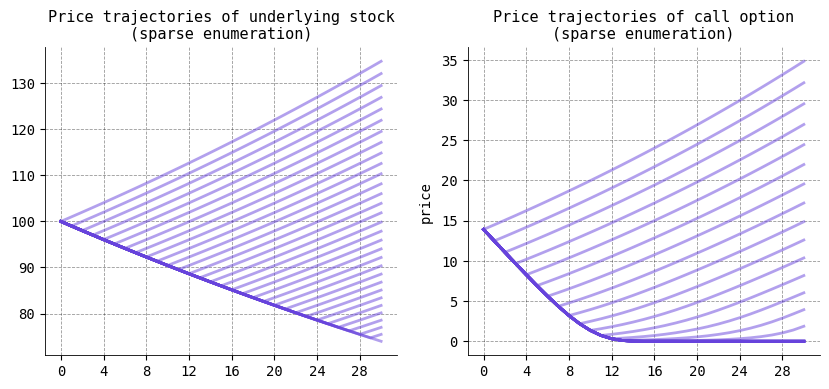

In [11]:
import matplotlib.pyplot as plt

sa.style.set_style()

S = sa.BinomialPricingModel.generate(
    initial_price=S_0,
    up_factor=1.01,
    down_factor=0.99,
    up_prob=0.55,
    risk_free_gross_return=1.005,
    enum_mode="sparse",
    mode="enum",
    length=30,
    name="S",
)

Phi = sa.Claim.european_option(model=S, strike=K, option_type="call")
_, _, V = Phi.hedging_portfolio()

_, axes = plt.subplots(ncols=2, figsize=(10, 4))

S.plot_trajectories(
    ax=axes[0],
    colors=[sa.style.purple],
    title="Price trajectories of underlying stock\n(sparse enumeration)",
    plot_kwargs={"alpha": 0.5},
)

V.plot_trajectories(
    ax=axes[1],
    colors=[sa.style.purple],
    y_label="price",
    title="Price trajectories of call option\n(sparse enumeration)",
    plot_kwargs={"alpha": 0.5},
)
plt.show()

### Pricing early-exercise claims

As we saw in the previous section, the price process $X_t$ of a non-early-exercise claim $\Phi_t$ is determined by the one-step martingale formulas
$$
X_t = \frac{1}{R}E_Q(X_{t+1} \mid \mathcal{F}_t), \quad X_T = \Phi_T, \tag{1}
$$
for $0 \leq t < T$. But if $\Phi_t$ allows early exercise, its price process $X_t$ is given instead by
$$
X_t = \max\left(\Phi_t,\ \frac{1}{R}\,E_Q\left(X_{t+1}\mid \mathcal{F}_t\right)\right), \quad X_T = \Phi_T, \tag{2}
$$
for $0 \leq t < T$.

The intuition for the modified formula $(2)$ again comes from the theory of replicating portfolios: The price process $X_t$ gives the least capital needed by the writer of the claim to hedge their short position in the claim. Indeed, at a given time $t$, the writer must be prepared to cover their liabilities in one of two outcomes: Either the claim holder exercises at time $t$ and the writer owes the payoff $\Phi_t$ to the holder, or the holder defers exercise to a future time. In the first case, the writer will require $X_t \geq \Phi_t$ to cover their liability, while in the second case, the writer will require enough capital to purchase a portfolio that replicates the claim's price $X_{t+1}$ at time $t+1$. From the theory in the previous section, we know that this will require
$$
X_t \geq \frac{1}{R}\,E_Q\left(X_{t+1}\mid \mathcal{F}_t\right).
$$
The modified formula (2) then follows.

In this context, the value $\Phi_t$ is called the *intrinsic value* of the claim at time $t$, while the discounted expectation
$$
V_t \stackrel{\text{def}}{=} \frac{1}{R}E_Q(X_{t+1} \mid \mathcal{F}_t)
$$
is called the *continuation value*. Notice that if $\Phi_t$ does not allow early exercise, then $V_t = X_t$ for all $t$ and the definition $(2)$ reduces to the martingale formulas $(1)$ obtained in the previous section for the value process of a replicating portfolio of a non-early-exercise claim. In other words, the two usages of $V_t$, in this section and the previous, do not clash in the situation where they both apply.

An enlightening alternative point of view on this pricing scheme uses the theory of *stopping times*. Intuitively, such an object is a random variable $\tau: \Omega \to \{0,1,\ldots,T,\infty\}$ such that, if $\tau(\omega)=t<\infty$, then the holder of the claim will exercise at time $t$ if they observe the partial price trajectory
$$
(S_0(\omega), S_1(\omega),\ldots,S_t(\omega)).
$$
Their choice to exercise can *only* depend on this partial price trajectory; it cannot depend on any future prices beyond time $t$. In particular, if $\omega'$ is a second sample point whose partial price trajectory
$$
(S_0(\omega'), S_1(\omega'),\ldots,S_t(\omega'))
$$
coincides with the one of $\omega$, then $\tau(\omega') = t$ as well. We allow stopping times to take the value $\infty$, which means that the holder will *never* exercise (i.e., they let the claim expire worthless.)

We may *evaluate* the contingent claim $\Phi_t$ at a stopping time $\tau$, yielding the random variable $\Phi_\tau$ which, evaluated at $\omega$, gives a payoff of $\Phi_{\tau(\omega)}$ to the claim holder at time $\tau(\omega)$. If the holder invested this money in the bond, they would have $R^{T-\tau}\Phi_\tau$ at maturity $T$. This essentially yields a non-early-exercise claim with payoff $R^{T-\tau}\Phi_\tau$ at maturity $T$. From the theory in the previous section, its risk-neutral price is
$$
\frac{1}{R^T} E_Q(R^{T-\tau}\Phi_\tau) = E_Q(R^{-\tau} \Phi_\tau).
$$
But the holder may exercise at *any* stopping time $\tau$, and so the risk-neutral price of the claim should be
$$
X_0 = \max_{\tau} \left(E_Q(R^{-\tau} \Phi_\tau)\right),\tag{3}
$$
where the maximum runs over all stopping times. One of the central theorems in the theory of risk-neutral pricing of early-exercise contingent claims states that the price given in $(3)$ is equal to the one described above in equations (2), and that the optimal stopping time $\tau$ that achieves the maximum is given by
$$
\tau(\omega)= \min \{ t \mid \Phi_t(\omega) \geq V_t(\omega)\},
$$
the first time that the intrinsic value of the claim exceeds its continuation value.

Let's see how all this theory is made concrete using SigAlg. We set up an American put option on a binomial pricing model over $T=8$ time steps.

In [12]:
S_0, u, d, p, R, T = 100, 1.08, 0.9, 0.7, 1.05, 8

S = sa.BinomialPricingModel.generate(
    initial_price=S_0,
    up_factor=u,
    down_factor=d,
    up_prob=p_u,
    risk_free_gross_return=R,
    mode="enum",
    length=T,
    name="S",
)

K = 90
Phi = sa.Claim.american_option(model=S, strike=K, option_type="put")

We compute the optimal stopping time $\tau$ by calling the `exercise_time` method on the claim.

In [13]:
tau = Phi.exercise_time()

print(tau)

Stopping time 'tau':
       tau
omega     
0      inf
1      inf
2      inf
3      inf
4      inf
...    ...
251    2.0
252    2.0
253    2.0
254    2.0
255    2.0

[256 rows x 1 columns]


We plot the price trajectories of the model, along with dots representing optimal stopping time.

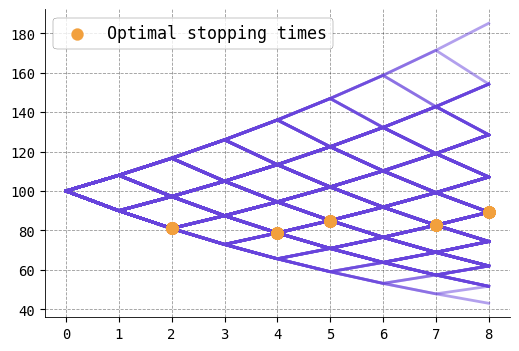

In [14]:
_, ax = plt.subplots(figsize=(6, 4))
S.plot_trajectories(ax=ax, colors=[sa.style.purple], plot_kwargs={"alpha": 0.5})
ax.scatter(
    tau,
    S.stopped(tau).last_rv,
    color=sa.style.amber,
    s=75,
    zorder=2,
    label="Optimal stopping times",
)
ax.legend()
plt.show()

Finally, we check that pricing formula
$$
X_0 = E_Q(R^{-\tau} \Phi_\tau)
$$
holds, where $\tau$ is the optimal stopping time.

In [15]:
Q = S.emm()
X = Phi.price_process()
np.allclose(X[0], Phi.discount(gross_return=R).at(tau).expectation(measure=Q))

True